In [97]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CODE_DIR = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

SCRIPTS_DIR = CODE_DIR / "scripts"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from environments.gridworld import GridNavi
from detect import Detect

from plotting import heatmap, annotate_heatmap
from stable_baselines3 import PPO
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from matplotlib.patches import Rectangle

ACTION_NAMES = {0: "noop", 1: "up", 2: "right", 3: "down", 4: "left"}

In [98]:
# task distributions as arrays of possible goals

def goal_positions(option, NUM_CELLS, starting_state=(0, 0)):
    if option == "og":
        sx, sy = int(starting_state[0]), int(starting_state[1])
        pos = [(x, y) for x in range(NUM_CELLS) for y in range(NUM_CELLS)]
        for dx in (-1, 0, 1):
            for dy in (-1, 0, 1):
                p = (sx + dx, sy + dy)
                if p in pos:
                    pos.remove(p)
        return pos
    if option == 1:
        # four corners
        return [
            (NUM_CELLS - 2, NUM_CELLS - 2),
            (NUM_CELLS - 2, NUM_CELLS - 1),
            (NUM_CELLS - 1, NUM_CELLS - 2),
            (NUM_CELLS - 1, NUM_CELLS - 1),
        ]
    if option == 2:
        return [
            (0, NUM_CELLS - 1),
            (0, NUM_CELLS - 2),
            (1, NUM_CELLS - 1),
            (1, NUM_CELLS - 2),
        ]
    raise ValueError(f"Unknown goal_positions option: {option}")


def dist_dirname(dist_id):
    """Folder name under data/exp4"""
    if dist_id == "og":
        return "task_dist_og"
    return f"task_dist{dist_id}"

In [99]:
NUM_CELLS = 5
MAX_STEPS = 15
STARTING_STATE = (0, 0)  # paper start; used for og goal support
N = NUM_CELLS * NUM_CELLS * MAX_STEPS
SEED = 42
DATA_DIR = CODE_DIR / "data" / "exp4"

def collect_tuples(task_dists, seed=SEED):
    """task_dists: dict {dist_id: list of goals}. Paper sparse reward; start from every cell."""
    rng = np.random.default_rng(seed)
    for dist_id, task_dist in task_dists.items():
        OUT_DIR = DATA_DIR / dist_dirname(dist_id)
        OUT_DIR.mkdir(parents=True, exist_ok=True)

        for task in task_dist:
            sar_rows = []
            for j in range(NUM_CELLS):
                for k in range(NUM_CELLS):
                    env = GridNavi(
                        num_cells=NUM_CELLS,
                        num_steps=MAX_STEPS,
                        distance_reward=True,
                        starting_state=(j, k),
                        possible_goals=task_dist,
                    )
                    env.reset_task(task=task)
                    obs, _ = env.reset()

                    for _ in range(MAX_STEPS):
                        action = int(rng.integers(env.action_space.n))
                        next_obs, reward, terminated, truncated, info = env.step(action)
                        sar_rows.append([obs[0], obs[1], action, reward, next_obs[0], next_obs[1]])
                        obs = next_obs
                        if terminated or truncated:
                            obs, _ = env.reset()

            sar = np.array(sar_rows[:N])  # (N, 6): [x, y, action, reward, x', y']
            np.save(OUT_DIR / f"goal_{task[0]}_{task[1]}.npy", sar)

In [100]:
# add more dists here (e.g. 2: goal_positions(2, NUM_CELLS)); collect_tuples / plots iterate this dict
task_dists = {
    "og": goal_positions("og", NUM_CELLS, starting_state=STARTING_STATE),
    1: goal_positions(1, NUM_CELLS),
    2: goal_positions(2, NUM_CELLS),
}

collect_tuples(task_dists)

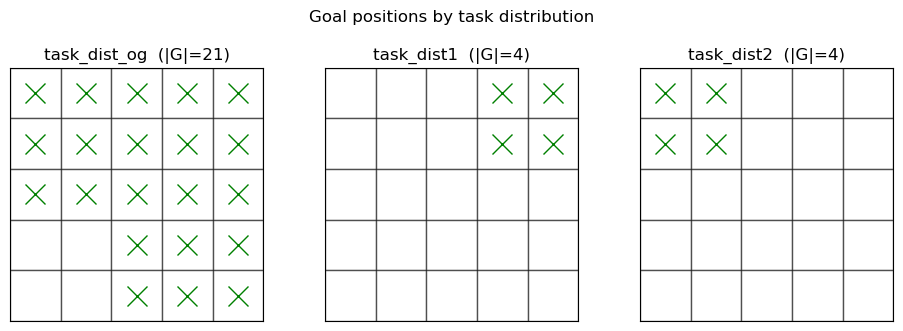

In [101]:
# visualise goal positions for each task distribution

n = len(task_dists)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3.2 * nrows))
axes = np.atleast_1d(axes).ravel()

for ax, (dist_id, goals) in zip(axes, task_dists.items()):
    for x in range(NUM_CELLS):
        for y in range(NUM_CELLS):
            ax.add_patch(Rectangle((x, y), 1, 1, facecolor="w", alpha=0.5, edgecolor="k"))

    for gx, gy in goals:
        ax.plot(gx + 0.5, NUM_CELLS - gy - 1 + 0.5, "gx", markersize=14, zorder=5)

    ax.set_xlim(0, NUM_CELLS)
    ax.set_ylim(NUM_CELLS, 0)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"{dist_dirname(dist_id)}  (|G|={len(goals)})")

for ax in axes[n:]:
    ax.axis("off")

fig.suptitle("Goal positions by task distribution", y=1.02)
fig.tight_layout()
plt.show()

In [102]:
# setting up the detection object
OBS_DIM = 2
ACTION_DIM = 5
REFERENCE_NUM = 100
VIZ = False

detect = Detect(
        reference_num=REFERENCE_NUM,
        input_dim=OBS_DIM,
        action_dim=ACTION_DIM,
        num_samples=N,
        sars_flag=True,
    )
detect.set_reference(OBS_DIM, REFERENCE_NUM, ACTION_DIM)

In [103]:
# calculate embeddings of each task in a distribution, and compute their mean
# we then get one vector that represents the task distribution

mean_embeddings = []
dist_ids = []
for dist_id, task_dist in task_dists.items():
    OUT_DIR = DATA_DIR / dist_dirname(dist_id)
    embeddings = []
    for goal in task_dist:
        sar = np.load(OUT_DIR / f"goal_{goal[0]}_{goal[1]}.npy")
        embedding = detect.lwe(sar, ACTION_DIM)
        embeddings.append(np.asarray(embedding).ravel())
        if VIZ:
            print(f"-------------------------------- goal: {goal} --------------------------------")
            print("SAR shape:", sar.shape)
            print("Embedding shape:", embedding.shape)
            print("First 5 values:", embedding[:5])
            print("-------------------------------------------------------------------------------")

    mean_embeddings.append(np.mean(np.stack(embeddings), axis=0))
    dist_ids.append(dist_id)

V = np.stack(mean_embeddings)
V = V / np.linalg.norm(V, axis=1, keepdims=True)
D = 1.0 - (V @ V.T)
df_mean = (
    pd.DataFrame(D, index=dist_ids, columns=dist_ids)
    .rename_axis("dist")
    .reset_index()
)
print("cosine distances between mean embeddings:")
display(df_mean.round(4))

cosine distances between mean embeddings:


,dist,og,1,2
0,og,0.0000,0.0238,0.0363
1,1,0.0238,0.0000,0.0727
2,2,0.0363,0.0727,-0.0000


In [104]:
mean_dists = []
dist_ids_within = []
for dist_id, task_dist in task_dists.items():
    OUT_DIR = DATA_DIR / dist_dirname(dist_id)
    embeddings = []
    for goal in task_dist:
        sar = np.load(OUT_DIR / f"goal_{goal[0]}_{goal[1]}.npy")
        embedding = detect.lwe(sar, ACTION_DIM)
        embeddings.append(np.asarray(embedding).ravel())
        if VIZ:
            print(f"-------------------------------- goal: {goal} --------------------------------")
            print("SAR shape:", sar.shape)
            print("Embedding shape:", embedding.shape)
            print("First 5 values:", embedding[:5])
            print("-------------------------------------------------------------------------------")

    E = np.stack([np.asarray(e).ravel() for e in embeddings])
    E = E / np.linalg.norm(E, axis=1, keepdims=True)
    cos_dists = [
        1 - np.dot(E[a], E[b])
        for a in range(len(E))
        for b in range(a + 1, len(E))
    ]
    mean_dists.append(float(np.mean(cos_dists)))
    dist_ids_within.append(dist_id)

df_within = pd.DataFrame(
    {"dist": dist_ids_within, "d": mean_dists},
)
print("mean pairwise cosine distances within each task distribution:")
display(df_within.round(4))

mean pairwise cosine distances within each task distribution:


,dist,d
0,og,0.1112
1,1,0.0789
2,2,0.0714


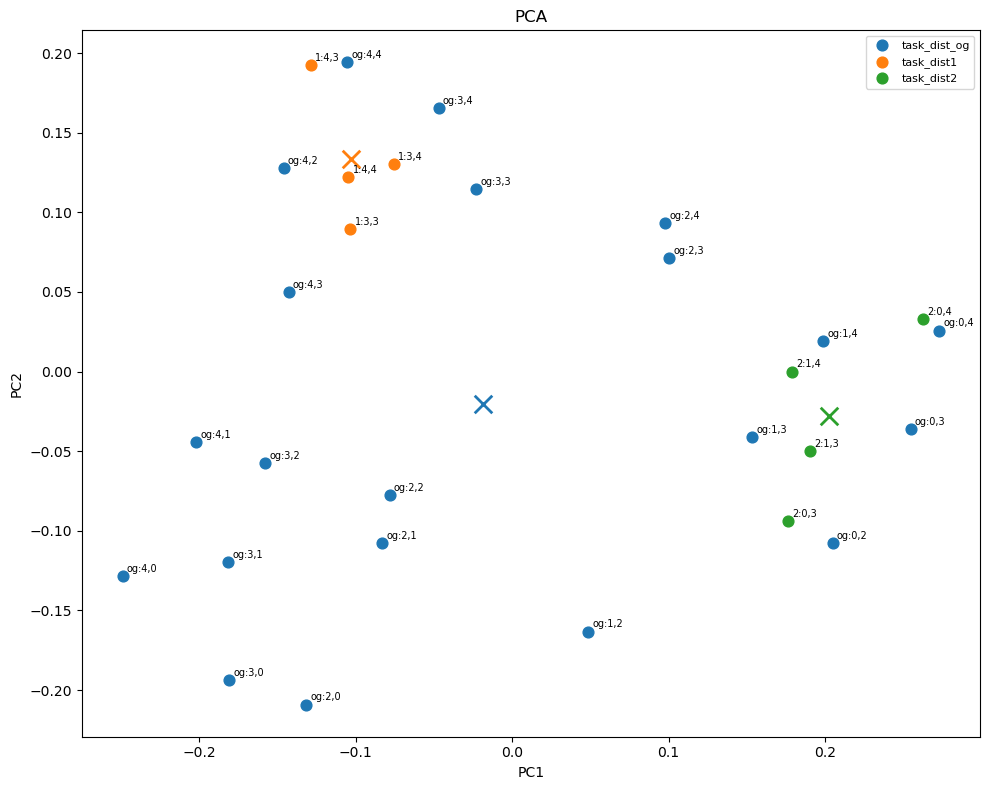

In [105]:
# PCA visualizations of task embeddings

rows, labels, goals = [], [], []
for dist_id, task_dist in task_dists.items():
    OUT_DIR = DATA_DIR / dist_dirname(dist_id)
    for goal in task_dist:
        sar = np.load(OUT_DIR / f"goal_{goal[0]}_{goal[1]}.npy")
        emb = np.asarray(detect.lwe(sar, ACTION_DIM)).ravel()
        rows.append(emb)
        labels.append(dist_id)
        goals.append(goal)

X = np.stack(rows)
labels = np.asarray(labels, dtype=object)

X_n = X / np.linalg.norm(X, axis=1, keepdims=True)

Z = PCA(n_components=2, random_state=0).fit_transform(X_n)

fig, ax = plt.subplots(figsize=(10, 8))
for dist_id in task_dists:
    mask = labels == dist_id
    sc = ax.scatter(Z[mask, 0], Z[mask, 1], s=60, label=dist_dirname(dist_id))
    color = sc.get_facecolors()[0]
    ax.scatter(
        Z[mask, 0].mean(),
        Z[mask, 1].mean(),
        s=160,
        marker="x",
        linewidths=2,
        c=[color],
    )
for (x, y), g, d in zip(Z, goals, labels):
    ax.annotate(f"{d}:{g[0]},{g[1]}", (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_title("PCA")
ax.legend(fontsize=8)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
fig.tight_layout()
plt.show()